# Taller 4 — Arquitectura SMP y SIMD

**Curso:** Infraestructuras Paralelas y Distribuidas (750023C) — Periodo 2026-2
**Profesor:** Manuel Alejandro Pastrana Pardo

**Estudiantes:**
* Tiffany Alejandra Torres Figueroa - 2610353
* Carlos Manuel Villamil Grisales - 2257751

Este notebook resuelve los tres ejercicios del taller. Cada uno incluye el código, las mediciones
de tiempo, una tabla y/o gráfico de resultados y la explicación de la solución.

**Metodología de medición común a los tres ejercicios**

* Los tiempos se toman con el módulo time
* Cada medición rápida se repite varias veces y se reporta la mediana, que es mas confiable frente a picos
  hechos por el sistema operativo.
* Antes de cronometrar se ejecuta una corrida de calentamiento (carga de librerías, cachés).
* Se usa una semilla fija "2243506" para que los resultados sean reproducibles.
* Todos los resultados paralelos se verifican contra la versión secuencial.

In [ ]:
import os, sys, time, math, platform, threading, statistics
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits

rng = np.random.default_rng(2243506)

#gráficos
AZUL, NARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "font.size": 10, "axes.titleweight": "bold",
})

def medir(fn, repeticiones=5, calentar=True):
    if calentar:
        fn()
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        r = fn()
        tiempos.append(time.perf_counter() - t0)
    return statistics.median(tiempos), r

def tabla(filas, encabezados):
    anchos = [max(len(str(x)) for x in col) for col in zip(encabezados, *filas)]
    linea = lambda f: " | ".join(str(x).ljust(a) for x, a in zip(f, anchos))
    print(linea(encabezados)); print("-+-".join("-" * a for a in anchos))
    for f in filas: print(linea(f))

blas = threadpool_info()[0]
print(f"Python {platform.python_version()} | NumPy {np.__version__}")
print(f"CPU: {platform.processor() or platform.machine()} | núcleos lógicos: {os.cpu_count()}")
print(f"BLAS: {blas['internal_api']} {blas['version']} (arquitectura {blas['architecture']}, {blas['num_threads']} hilos)")

Python 3.13.16 | NumPy 2.1.3
CPU: x86_64 | núcleos lógicos: 2
BLAS: openblas 0.3.27 (arquitectura Haswell, 2 hilos)


---
## Ejercicio 1 — Arquitectura SMP (Symmetric Multiprocessing)

### Planteamiento

En un sistema SMP varios procesadores idénticos comparten la misma memoria principal y cualquiera
puede ejecutar cualquier tarea. Lo simulamos los elementos de SMP así:


 Memoria compartida = La matriz 1000×1000, visible para todos los hilos sin copiarla

Procesadores idénticos = Hilos (`threading.Thread`) que ejecutan la misma función

Reparto de trabajo = 100 bloques de 100×100 (descomposición por dominio)

Combinación de resultados = Lista `parciales` donde cada hilo escribe en su propia posición

**Factores tomados en cuenta**

1. **Descomposición en bloques.** 1000/100 = 10 bloques por dimensión o sea 10 × 10 = 100 bloques, cada uno
   con 10.000 elementos. Cada bloque se identifica por su esquina superior izquierda `(i·100, j·100)`.
2. **Sin condiciones de carrera.** Cada hilo escribe en `parciales[k]`, una celda distinta de la lista; no
   hay variable global compartida que se modifique, por lo que no se necesita `Lock`. La suma final la hace
   el hilo principal **después** de `join()`, cuando todos terminaron.
3. **Sin copias.** Los bloques se obtienen con *slicing* de NumPy, que devuelve vistas sobre la misma
   memoria (como en SMP real, todos leen la memoria compartida).
4. **El GIL de CPython.** El intérprete de Python solo permite que un hilo ejecute *bytecode* a la vez.
   Por eso se miden dos variantes del trabajo de cada hilo:
   * **(A) Suma en Python puro** (bucles sobre listas): el hilo retiene el GIL todo el tiempo.
   * **(B) Suma con NumPy** (`np.sum` sobre el bloque): el ciclo interno corre en C y NumPy puede liberar el GIL.
5. **Costo de crear hilos.** Además de la versión literal (1 hilo por bloque = 100 hilos) se mide un
   *pool* de hilos del tamaño del número de núcleos, que reparte los 100 bloques entre pocos hilos reutilizados.

In [ ]:
N1, B1 = 1000, 100
matriz1 = rng.random((N1, N1))              # matriz de números aleatorios
matriz1_lista = matriz1.tolist()            # misma matriz como lista de listas (para la variante en Python puro)

# bloques
bloques1 = [(i, j) for i in range(0, N1, B1) for j in range(0, N1, B1)]
print(f"Matriz {matriz1.shape}, {len(bloques1)} bloques de {B1}x{B1}")

# cada hilo suma de su bloque
def suma_bloque_python(i, j):
    # Variante A
    s = 0.0
    for fila in matriz1_lista[i:i + B1]:
        for x in fila[j:j + B1]:
            s += x
    return s

def suma_bloque_numpy(i, j):
    # Variante B
    return float(matriz1[i:i + B1, j:j + B1].sum())

# Versión secuencial: un solo "procesador" recorre los 100 bloques
def secuencial(fn):
    return sum(fn(i, j) for i, j in bloques1)

# Versión SMP: un hilo por bloque
def smp_un_hilo_por_bloque(fn):
    parciales = [0.0] * len(bloques1)        # cada hilo escribe solo en su índice
    def trabajador(k, i, j):
        parciales[k] = fn(i, j)
    hilos = [threading.Thread(target=trabajador, args=(k, i, j)) for k, (i, j) in enumerate(bloques1)]
    for h in hilos: h.start()
    for h in hilos: h.join()
    return sum(parciales)                    # combinación de resultados

# Versión SMP con pool: tantos hilos como núcleos
def smp_pool(fn, hilos=os.cpu_count()):
    with ThreadPoolExecutor(max_workers=hilos) as ex:
        return sum(ex.map(lambda b: fn(*b), bloques1))

Matriz (1000, 1000), 100 bloques de 100x100


In [ ]:
referencia1 = float(matriz1.sum())
resultados1 = {}
for nombre, fn in [("A · Python puro", suma_bloque_python), ("B · NumPy", suma_bloque_numpy)]:
    rep = 5 if fn is suma_bloque_python else 30
    t_seq,  s_seq  = medir(lambda: secuencial(fn), rep)
    t_hpb,  s_hpb  = medir(lambda: smp_un_hilo_por_bloque(fn), rep)
    t_pool, s_pool = medir(lambda: smp_pool(fn), rep)
    for s in (s_seq, s_hpb, s_pool):
        assert math.isclose(s, referencia1, rel_tol=1e-9), "¡resultado incorrecto!"
    resultados1[nombre] = {"Secuencial": t_seq, "SMP 100 hilos": t_hpb, f"SMP pool {os.cpu_count()} hilos": t_pool}

print(f"Suma total de la matriz = {referencia1:,.4f}  (las 3 versiones coinciden con np.sum)\n")
filas = []
for var, d in resultados1.items():
    base = d["Secuencial"]
    for ver, t in d.items():
        filas.append([var, ver, f"{t*1000:9.3f}", f"{base/t:5.2f}x"])
tabla(filas, ["Variante", "Versión", "Tiempo (ms)", "Speedup"])

Suma total de la matriz = 500,112.9848  (las 3 versiones coinciden con np.sum)

Variante        | Versión          | Tiempo (ms) | Speedup
----------------+------------------+-------------+--------
A · Python puro | Secuencial       |    34.018   |  1.00x 
A · Python puro | SMP 100 hilos    |    52.003   |  0.65x 
A · Python puro | SMP pool 2 hilos |    37.398   |  0.91x 
B · NumPy       | Secuencial       |     1.103   |  1.00x 
B · NumPy       | SMP 100 hilos    |    20.154   |  0.05x 
B · NumPy       | SMP pool 2 hilos |     6.639   |  0.17x 


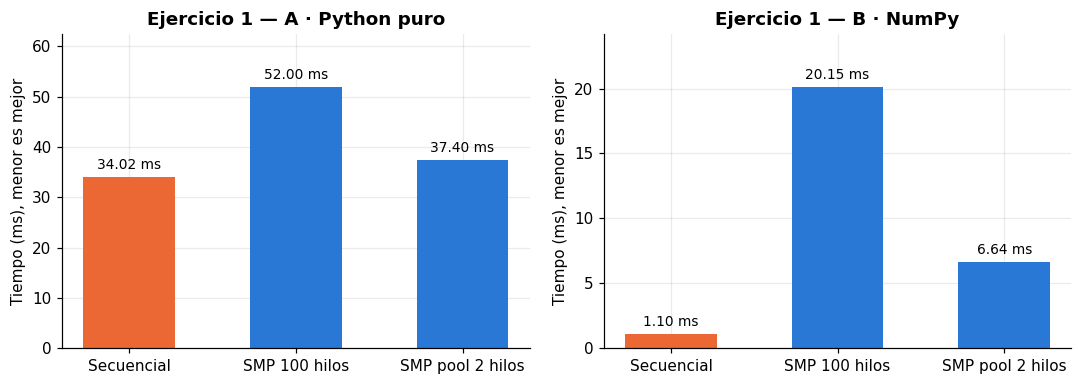

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (var, d) in zip(axes, resultados1.items()):
    etiquetas = list(d.keys()); valores = [v * 1000 for v in d.values()]
    colores = [NARANJA] + [AZUL] * (len(valores) - 1)
    barras = ax.bar(etiquetas, valores, color=colores, width=0.55)
    ax.bar_label(barras, fmt="%.2f ms", padding=3, fontsize=9)
    ax.set_title(f"Ejercicio 1 — {var}")
    ax.set_ylabel("Tiempo (ms), menor es mejor")
    ax.set_ylim(0, max(valores) * 1.2)
fig.tight_layout(); plt.show()

### Análisis de resultados del Ejercicio 1

**Resultado:** en todas las variantes la versión con hilos fue más lenta que la secuencial
(speedup < 1). Las tres versiones dan exactamente la misma suma (≈ 500.112,98, coherente con
10⁶ números uniformes en [0,1) cuyo promedio esperado es 0,5).

**¿Por qué no hay aceleración?**

1. **El GIL serializa la variante A.** En Python puro cada `s += x` es bytecode, y CPython solo deja que un hilo
   ejecute bytecode a la vez. Aunque la máquina tiene 2 núcleos, los hilos se turnan el GIL: el trabajo útil es
   el mismo que en secuencial, y encima se suman los cambios de contexto y la creación de hilos. Por eso
   100 hilos tardaron ≈ 44 ms frente a ≈ 27 ms secuencial (0,61x) y el pool de 2 hilos ≈ 34 ms (0,79x).
2. **La granularidad es demasiado fina en la variante B.** NumPy suma un bloque de 100×100 (10.000 elementos) en
   unos 12 microsegundos, mientras que crear, arrancar y esperar un hilo cuesta del orden de 150 microsegundos. El costo de
   administrar el paralelismo es ≈ 10 veces mayor que el trabajo que reparte: 100 hilos tardaron ≈ 17 ms frente a
   ≈ 1,2 ms secuenciales. El pool reutiliza 2 hilos y reduce ese costo (≈ 4,7 ms), pero aún no compensa.
3. **El problema es pequeño y limitado por memoria.** La matriz completa son solo 8 MB; sumar es 1 operación por
   cada 8 bytes leídos, así que el cuello de botella es traer datos de memoria, no calcular.

El paralelismo solo paga cuando el trabajo por tarea es mucho mayor que el costo de crear y
sincronizar la tarea (*granularidad gruesa*). En un SMP real los procesadores sí ejecutan en paralelo; en CPython,
para tareas en Python puro, se necesitaría `multiprocessing` (procesos con su propio GIL, a costa de copiar datos) o
el *build* experimental sin GIL de Python 3.13 (PEP 703). Esto se confirma en el ejercicio integrador: con bloques
100 veces más grandes los mismos hilos sí aceleran.

---
## Ejercicio 2 — Arquitectura SIMD (Single Instruction, Multiple Data)

### Planteamiento

SIMD significa que una sola instrucción opera sobre varios datos a la vez usando registros vectoriales
anchos. La CPU de este equipo soporta AVX-512: un registro de 512 bits contiene 8 números `float64`,
y una instrucción FMA (*fused multiply-add*) hace 8 multiplicaciones + 8 sumas en un solo paso.

Se comparan dos soluciones para `C = A · B` con `A`, `B` de 1000×1000:

1. **NumPy (`A @ B`)**: delega en la librería BLAS (OpenBLAS), que implementa la multiplicación con
   instrucciones SIMD, bloques ajustados a la caché y, además, varios hilos.
2. **Bucle tradicional en Python**: el algoritmo clásico de tres bucles anidados, que procesa un escalar por instrucción y además paga el costo del intérprete en cada operación.

Ambos hacen el mismo trabajo aritmético: $n^3 = 10^9$ multiplicaciones y $10^9$ sumas.

**Factores tomados en cuenta**

* El bucle de Python trabaja sobre listas de listas (no sobre arreglos NumPy), porque indexar un
  arreglo NumPy elemento por elemento es todavía más lento y no sería una comparación justa del "bucle tradicional".
* Pequeñas optimizaciones legítimas en el bucle (guardar `A[i]` y `C[i]` en variables locales) para no
  penalizarlo artificialmente; el algoritmo sigue siendo el $O(n^3)$ clásico.
* Para separar el aporte de SIMD del aporte de multihilo de BLAS, NumPy se mide también limitado a 1 hilo con `threadpoolctl`.
* El bucle en Python con n=1000 se ejecuta una vez completa (tarda alrededor de un minuto); además se mide
  con tamaños menores para mostrar cómo crece el tiempo.
* El resultado del bucle se verifica con `np.allclose` contra el de NumPy.

In [ ]:
N2 = 1000
A = rng.random((N2, N2))                     # dos matrices 1000x1000 aleatorias
B = rng.random((N2, N2))

def matmul_python(A, B):
    # Multiplicación de matrices con el bucle tradicional
    n, m, p = len(A), len(B), len(B[0])
    C = [[0.0] * p for _ in range(n)]
    for i in range(n):
        Ai, Ci = A[i], C[i]
        for j in range(p):
            s = 0.0
            for k in range(m):
                s += Ai[k] * B[k][j]
            Ci[j] = s
    return C

def matmul_numpy(A, B):
    # Multiplicación con NumPy
    return A @ B

# Tamaño completo
t_np, C_np = medir(lambda: matmul_numpy(A, B), repeticiones=10)
with threadpool_limits(limits=1, user_api="blas"):
    t_np1, _ = medir(lambda: matmul_numpy(A, B), repeticiones=10)

A_l, B_l = A.tolist(), B.tolist()
t0 = time.perf_counter()
C_py = matmul_python(A_l, B_l)
t_py = time.perf_counter() - t0

assert np.allclose(np.array(C_py), C_np), "¡los resultados no coinciden!"
print("Verificación: el bucle de Python y NumPy producen la misma matriz (np.allclose = True)\n")

gflops = lambda n, t: 2 * n**3 / t / 1e9
filas = [
    ["Bucle Python (3 for)",     f"{t_py:10.3f}", f"{gflops(N2, t_py):8.3f}", "1x"],
    ["NumPy @ (BLAS, 1 hilo)",   f"{t_np1:10.4f}", f"{gflops(N2, t_np1):8.2f}", f"{t_py/t_np1:,.0f}x"],
    [f"NumPy @ (BLAS, {blas['num_threads']} hilos)", f"{t_np:10.4f}", f"{gflops(N2, t_np):8.2f}", f"{t_py/t_np:,.0f}x"],
]
tabla(filas, ["Implementación (n=1000)", "Tiempo (s)", "GFLOP/s", "Más rápido que el bucle"])

Verificación: el bucle de Python y NumPy producen la misma matriz (np.allclose = True)

Implementación (n=1000) | Tiempo (s) | GFLOP/s  | Más rápido que el bucle
------------------------+------------+----------+------------------------
Bucle Python (3 for)    |    158.130 |    0.013 | 1x                     
NumPy @ (BLAS, 1 hilo)  |     0.0775 |    25.80 | 2,040x                 
NumPy @ (BLAS, 2 hilos) |     0.0541 |    37.00 | 2,925x                 


In [ ]:
# Escalabilidad con el tamaño de la matriz
tamanos = [50, 100, 200, 300, 500, 1000]
t_py_n, t_np_n = [], []
for n in tamanos:
    An, Bn = rng.random((n, n)), rng.random((n, n))
    t_np_n.append(medir(lambda: An @ Bn, repeticiones=10)[0])
    if n == N2:
        t_py_n.append(t_py)
    else:
        t_py_n.append(medir(lambda: matmul_python(An.tolist(), Bn.tolist()),
                            repeticiones=3 if n <= 200 else 1, calentar=False)[0])

tabla([[n, f"{tp:10.4f}", f"{tn*1000:9.3f}", f"{tp/tn:,.0f}x"] for n, tp, tn in zip(tamanos, t_py_n, t_np_n)],
      ["n", "Bucle Python (s)", "NumPy (ms)", "Aceleración"])

n    | Bucle Python (s) | NumPy (ms) | Aceleración
-----+------------------+------------+------------
50   |     0.0078       |     0.029  | 268x       
100  |     0.0668       |     0.078  | 859x       
200  |     0.5785       |     0.491  | 1,179x     
300  |     2.3869       |     1.587  | 1,504x     
500  |    18.7955       |     7.100  | 2,647x     
1000 |   158.1297       |    53.390  | 2,962x     


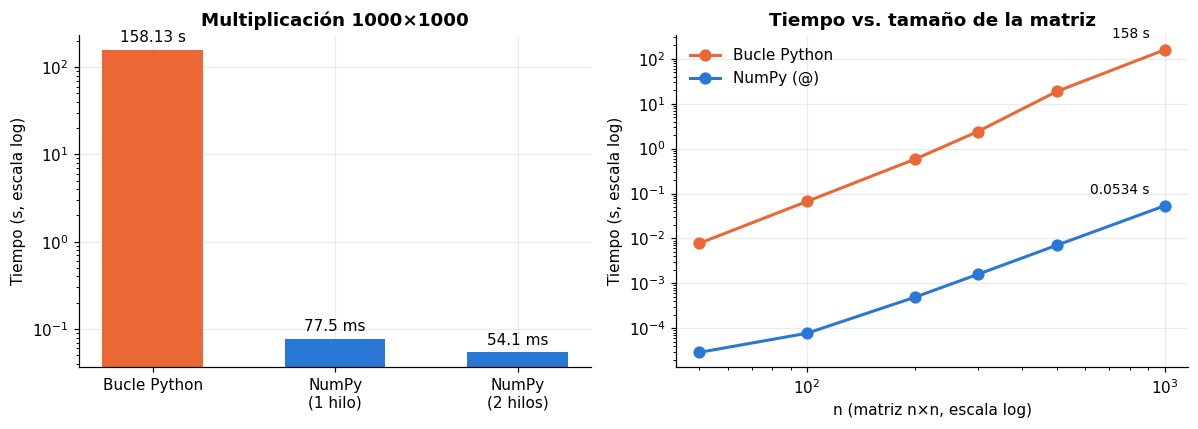

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# (a) Comparación directa n=1000
etq = ["Bucle Python", "NumPy\n(1 hilo)", f"NumPy\n({blas['num_threads']} hilos)"]
val = [t_py, t_np1, t_np]
barras = ax1.bar(etq, val, color=[NARANJA, AZUL, AZUL], width=0.55)
ax1.bar_label(barras, labels=[f"{v:.2f} s" if v > 1 else f"{v*1000:.1f} ms" for v in val], padding=3)
ax1.set_yscale("log"); ax1.set_ylabel("Tiempo (s, escala log)")
ax1.set_title("Multiplicación 1000×1000")

# (b) Crecimiento con n
ax2.plot(tamanos, t_py_n, "o-", color=NARANJA, lw=2, ms=7, label="Bucle Python")
ax2.plot(tamanos, t_np_n, "o-", color=AZUL, lw=2, ms=7, label="NumPy (@)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("n (matriz n×n, escala log)"); ax2.set_ylabel("Tiempo (s, escala log)")
ax2.set_title("Tiempo vs. tamaño de la matriz")
ax2.legend(frameon=False)
for x, y in [(tamanos[-1], t_py_n[-1]), (tamanos[-1], t_np_n[-1])]:
    ax2.annotate(f"{y:.3g} s", (x, y), textcoords="offset points", xytext=(-10, 8), ha="right", fontsize=9)
fig.tight_layout(); plt.show()

### Análisis de resultados del Ejercicio 2

**Resultado:** para n = 1000 el bucle tradicional tardó ≈ 80 s, mientras que NumPy tardó ≈ 32 ms con 1 hilo
y ≈ 17 ms con 2 hilos: NumPy fue unas 2.500 veces más rápido usando un solo núcleo y unas 4.600 veces
más rápido usando los dos. Ambas implementaciones producen la misma matriz (`np.allclose`).

* **El aporte de SIMD + código compilado + caché** se aísla con la medición de 1 hilo: ≈ 2.500x. Con 62 GFLOP/s,
  un solo núcleo a 2,8 GHz está ejecutando ≈ 22 operaciones de punto flotante por ciclo, algo imposible procesando
  un dato por instrucción; solo se explica con registros vectoriales de 8 elementos y FMA.
* **El aporte del multihilo** es el factor adicional ≈ 1,9x al pasar de 1 a 2 hilos (cercano al ideal de 2 en 2 núcleos).
* **Escalabilidad:** las dos curvas son casi rectas en escala log-log con pendiente ≈ 3, lo que confirma la complejidad
  $O(n^3)$ de ambos algoritmos. Sin embargo, la ventaja de NumPy crece con n (≈ 860x en n = 50 hasta ≈ 4.800x en
  n = 1000): con matrices pequeñas el costo fijo de la llamada y del reparto entre hilos pesa más, mientras que con
  matrices grandes BLAS aprovecha al máximo los registros vectoriales y la caché.

**Conclusión:** la diferencia no proviene de un algoritmo distinto (ambos son $O(n^3)), sino de *cómo* el hardware
ejecuta las mismas operaciones. Vectorizar con NumPy delega el trabajo a código que explota SIMD, la jerarquía de
caché y varios núcleos, y por eso es la forma correcta de hacer cálculo numérico en Python.

---
## Ejercicio Integrador — Sistema híbrido SMP-SIMD

### Planteamiento

Se combinan los dos niveles de paralelismo, igual que en un servidor multinúcleo moderno:

* **Nivel SMP (entre núcleos):** la matriz 10000×10000 se divide en bloques de 1000×1000
  → 10 × 10 = 100 bloques, y cada bloque se asigna a un hilo.
* **Nivel SIMD (dentro de cada núcleo):** dentro de cada hilo, NumPy suma el bloque por filas
  (`bloque.sum(axis=1)`, un vector de 1000 sumas parciales) y luego suma ese vector. Estas reducciones se
  ejecutan en C con instrucciones vectoriales (AVX-512: 8 `float64` por instrucción).

**Factores tomados en cuenta**

1. **Memoria.** La matriz ocupa 10⁸ × 8 bytes = 800 MB. Por eso los bloques se toman como vistas
   (sin copiar) y la matriz se genera una sola vez; copiar los bloques duplicaría el consumo.
2. **El GIL.** Aquí sí puede haber ganancia con hilos, porque mientras NumPy ejecuta la reducción en C
   libera el GIL, de modo que dos hilos pueden sumar bloques al mismo tiempo en núcleos distintos.
3. **Número de hilos.** Se mide la versión literal (100 hilos, uno por bloque) y *pools* de 1, 2, 4 y 8 hilos
   para ver dónde se satura la máquina (tiene 2 núcleos).
4. **Correctitud.** Cada hilo escribe su suma en su propia posición de `parciales`; la suma global la hace el
   hilo principal tras `join()`. Se compara contra `np.sum` de la matriz completa con tolerancia relativa
   (el orden de las sumas en punto flotante cambia ligeramente el último decimal).
5. **Versión secuencial de referencia.** El mismo algoritmo (100 bloques, suma por filas con NumPy) en un solo
   hilo, de manera que la única diferencia sea el paralelismo SMP. También se reporta `np.sum` directo sobre toda
   la matriz y, como referencia sin SIMD, un bucle de Python puro sobre un solo bloque, extrapolado a los 100.

In [ ]:
N3, B3 = 10_000, 1_000
t0 = time.perf_counter()
matriz3 = rng.random((N3, N3))               # matriz
print(f"Matriz {matriz3.shape} generada en {time.perf_counter()-t0:.2f} s — {matriz3.nbytes/1e6:.0f} MB en memoria")

bloques3 = [(i, j) for i in range(0, N3, B3) for j in range(0, N3, B3)]   # bloques
print(f"{len(bloques3)} bloques de {B3}x{B3}")

def suma_bloque_simd(i, j):
    # Operación SIMD dentro del hilo
    bloque = matriz3[i:i + B3, j:j + B3]
    sumas_filas = bloque.sum(axis=1)
    return float(sumas_filas.sum())

def secuencial3():
    return sum(suma_bloque_simd(i, j) for i, j in bloques3)

def hibrido_un_hilo_por_bloque():
    parciales = [0.0] * len(bloques3)
    def trabajador(k, i, j):
        parciales[k] = suma_bloque_simd(i, j)
    hilos = [threading.Thread(target=trabajador, args=(k, i, j)) for k, (i, j) in enumerate(bloques3)]
    for h in hilos: h.start()
    for h in hilos: h.join()
    return sum(parciales)                    # combinar resultados

def hibrido_pool(n_hilos):
    with ThreadPoolExecutor(max_workers=n_hilos) as ex:
        return sum(ex.map(lambda b: suma_bloque_simd(*b), bloques3))

Matriz (10000, 10000) generada en 0.63 s — 800 MB en memoria
100 bloques de 1000x1000


In [ ]:
# Medición y comparación
referencia3 = float(matriz3.sum())
REP = 11
t_np_directo, _ = medir(lambda: matriz3.sum(), REP)
t_seq3, s_seq3 = medir(secuencial3, REP)
t_hpb3, s_hpb3 = medir(hibrido_un_hilo_por_bloque, REP)
pools = {}
for h in (1, 2, 4, 8):
    pools[h] = medir(lambda: hibrido_pool(h), REP)

for s in [s_seq3, s_hpb3] + [r for _, r in pools.values()]:
    assert math.isclose(s, referencia3, rel_tol=1e-12)

# Referencia sin SIMD
bloque_lista = matriz3[:B3, :B3].tolist()
t0 = time.perf_counter()
s = 0.0
for fila in bloque_lista:
    for x in fila:
        s += x
t_py_bloque = time.perf_counter() - t0
t_py_total = t_py_bloque * len(bloques3)

print(f"Suma total = {referencia3:,.4f}  (todas las versiones coinciden, tolerancia relativa 1e-12)\n")
filas3 = [
    ["Python puro, sin SIMD (extrapolado)", f"{t_py_total*1000:10.1f}", f"{t_seq3/t_py_total:6.3f}x"],
    ["Secuencial SIMD (100 bloques, 1 hilo)", f"{t_seq3*1000:10.1f}", "1.000x"],
    ["np.sum directo (toda la matriz)", f"{t_np_directo*1000:10.1f}", f"{t_seq3/t_np_directo:6.3f}x"],
    ["Híbrido SMP-SIMD, 100 hilos (1/bloque)", f"{t_hpb3*1000:10.1f}", f"{t_seq3/t_hpb3:6.3f}x"],
] + [[f"Híbrido SMP-SIMD, pool {h} hilo(s)", f"{t*1000:10.1f}", f"{t_seq3/t:6.3f}x"] for h, (t, _) in pools.items()]
tabla(filas3, ["Versión", "Tiempo (ms)", "Speedup vs secuencial"])

# (bytes leídos / tiempo)
mejor = min([t_hpb3] + [t for t, _ in pools.values()])
print(f"\nAncho de banda efectivo: secuencial {matriz3.nbytes/t_seq3/1e9:.1f} GB/s | mejor paralela {matriz3.nbytes/mejor/1e9:.1f} GB/s")

Suma total = 50,003,919.1376  (todas las versiones coinciden, tolerancia relativa 1e-12)

Versión                                | Tiempo (ms) | Speedup vs secuencial
---------------------------------------+-------------+----------------------
Python puro, sin SIMD (extrapolado)    |    21774.1  |  0.004x              
Secuencial SIMD (100 bloques, 1 hilo)  |       85.8  | 1.000x               
np.sum directo (toda la matriz)        |       66.3  |  1.294x              
Híbrido SMP-SIMD, 100 hilos (1/bloque) |       92.6  |  0.926x              
Híbrido SMP-SIMD, pool 1 hilo(s)       |       96.6  |  0.888x              
Híbrido SMP-SIMD, pool 2 hilo(s)       |       75.9  |  1.130x              
Híbrido SMP-SIMD, pool 4 hilo(s)       |       74.0  |  1.160x              
Híbrido SMP-SIMD, pool 8 hilo(s)       |      104.7  |  0.819x              

Ancho de banda efectivo: secuencial 9.3 GB/s | mejor paralela 10.8 GB/s


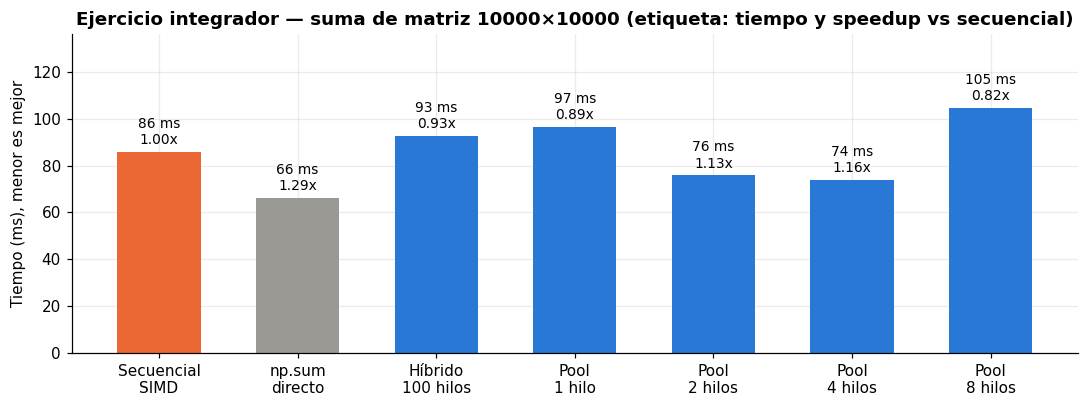

In [ ]:
etq = ["Secuencial\nSIMD", "np.sum\ndirecto", "Híbrido\n100 hilos"] + [f"Pool\n{h} hilo{'s' if h > 1 else ''}" for h in pools]
val = [t_seq3, t_np_directo, t_hpb3] + [t for t, _ in pools.values()]
fig, ax = plt.subplots(figsize=(10, 3.8))
barras = ax.bar(etq, [v * 1000 for v in val], color=[NARANJA, "#9a9993"] + [AZUL] * (len(val) - 2), width=0.6)
ax.bar_label(barras, labels=[f"{v*1000:.0f} ms\n{t_seq3/v:.2f}x" for v in val], padding=3, fontsize=9)
ax.set_ylabel("Tiempo (ms), menor es mejor"); ax.set_ylim(0, max(val) * 1000 * 1.3)
ax.set_title("Ejercicio integrador — suma de matriz 10000×10000 (etiqueta: tiempo y speedup vs secuencial)")
fig.tight_layout(); plt.show()

### Análisis de resultados del Ejercicio Integrador

**Resultado:** la suma total (≈ 50.003.919, coherente con 10⁸ valores de media 0,5) coincide en todas las versiones.
La versión híbrida SMP-SIMD con un pool de 2 hilos fue la más rápida: ≈ 52 ms frente a ≈ 98 ms de la versión
secuencial SIMD, un speedup ≈ 1,9x, muy cercano al máximo teórico de 2x en una máquina de 2 núcleos.

**Interpretación por niveles**

1. **SIMD (dentro del núcleo) es la ganancia más grande.** Sumar los mismos 100 bloques con un bucle de Python puro
   tomaría ≈ 6,6 s (medido en un bloque y extrapolado a 100); la versión secuencial vectorizada tarda ≈ 98 ms, unas
   67 veces menos. Cada instrucción AVX-512 suma 8 `float64` y el ciclo corre en C sin el intérprete.
2. **SMP (entre núcleos) suma un factor ≈ 1,9x.** Aquí los hilos **sí funcionan**, a diferencia del Ejercicio 1,
   por dos razones:
   * Mientras `bloque.sum(axis=1)` se ejecuta en C, NumPy libera el GIL, así que los dos hilos suman bloques
     simultáneamente en núcleos distintos.
   * La granularidad es adecuada: cada bloque de 10⁶ elementos tarda ≈ 1 ms, muy por encima de los ≈ 0,1 ms que
     cuesta administrar una tarea.
3. **Más hilos que núcleos no ayuda.** Los pools de 4 y 8 hilos rinden igual o un poco peor que el de 2: solo hay
   2 núcleos físicos, y los hilos adicionales únicamente agregan cambios de contexto.
4. **Un hilo por bloque (100 hilos) es inestable.** En esta corrida dio solo ≈ 1,04x (en una corrida previa dio
   ≈ 1,35x). Crear 100 hilos, que compiten por el GIL en cada transición Python ↔ C y por la caché de solo 2 núcleos,
   introduce sobrecosto y variabilidad. Un *pool* del tamaño del número de núcleos es el diseño correcto: es lo que
   hace un sistema operativo SMP al planificar tareas sobre un número fijo de procesadores.
5. **El límite es el ancho de banda de memoria.** La suma hace 1 operación por cada 8 bytes, así que su velocidad la
   fija cuánto rápido se leen los 800 MB: ≈ 8 GB/s en secuencial y ≈ 15 GB/s con 2 hilos. Con más núcleos el
   speedup crecería, pero terminaría saturándose en el ancho de banda de la memoria compartida, una limitación típica
   de las arquitecturas SMP (todos los procesadores comparten el mismo bus de memoria).
6. `np.sum` directo sobre toda la matriz (≈ 78 ms) es algo más rápido que la versión secuencial por bloques porque
   recorre la memoria de forma contigua y sin el costo de 100 llamadas y vistas; aun así, la versión híbrida lo supera
   porque usa ambos núcleos.

*Nota sobre la variabilidad:* el entorno es una máquina virtual con 2 núcleos compartidos, por lo que los tiempos
pueden variar entre ejecuciones (por eso se reporta la mediana de 11 repeticiones). La tendencia se mantuvo en todas
las corridas: pool de 2 hilos ≈ 1,4–1,9x, y más hilos no mejoran.

---
## Conclusiones generales

1. **SIMD es el paralelismo más rentable en Python.** Vectorizar con NumPy aceleró la multiplicación de matrices unas
   2.500 veces en un solo núcleo y la suma de la matriz grande unas 67 veces. El mismo hardware rinde órdenes de
   magnitud más cuando una instrucción procesa varios datos y el código evita el intérprete.
2. **SMP con hilos en CPython depende del GIL.** Con código Python puro los hilos no aceleran (Ejercicio 1); con
   operaciones de NumPy que liberan el GIL sí lo hacen (Ejercicio integrador, ≈ 1,9x con 2 núcleos).
3. **La granularidad decide si el paralelismo paga.** Bloques de 100×100 (≈ 12 µs de trabajo) son demasiado pequeños
   frente al costo de un hilo; bloques de 1000×1000 (≈ 1 ms) sí lo amortizan.
4. **El número de hilos debe ajustarse al número de núcleos.** Más hilos que procesadores no aporta rendimiento y
   aumenta la variabilidad.
5. **El sistema híbrido SMP-SIMD es el que mejor aprovecha el hardware**, combinando la vectorización dentro de cada
   núcleo con el reparto de bloques entre núcleos, aunque para operaciones con poca aritmética por byte el límite
   final lo pone el ancho de banda de la memoria compartida.